In [ ]:
print("hello world")

In [36]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
import os
from matplotlib.patches import Rectangle
import re
import sys
import warnings
warnings.filterwarnings('ignore')
import scipy.stats as sc

In [37]:

sys.path.append(r"C:/Users/mtuffery/python_utils/")
from calcium_imaging import dFoverF

#need to replace with the actual function

In [38]:


data_root_directory = "S:/mtuffery/relaxin_2p/rln3aqf2quasgc6f/Visual_stimulations_rln3a_2025/"

protocol_directories = [
    "black_white_diff_intensties/",
    "dark_stim/",
    "gratings/",
    "long_dark/",
    "loomings_black_and_white/",
    "ramps/",
    "DARK_1HOUR/",
    "receptive_fields",
    "NI_spontaneous",
    "bilat_eye_ablation"
]

In [39]:

protocol_metadata = {}
protocol_traces = {}


load_raw_data =True
write_summary_csvs = True




if load_raw_data:


    
    for protocol_directory in protocol_directories:
        fish_directories = [trace_selection.path for trace_selection in os.scandir(data_root_directory+protocol_directory) if trace_selection.is_dir() ]

        protocol_metadata_frame = pd.DataFrame()
        protocol_trace_frame = pd.DataFrame()
        
        for fish_directory in fish_directories:
            if len(re.findall("excluded", fish_directory)) == 0:
                fish_identifier = fish_directory.split("/")[-1]
    
                #------background trace-------------------
                background_trace = pd.read_csv(fish_directory+"/Data/background_trace.csv")["Mean"]

                #-------info about position---------------

                fish_metadata = pd.read_csv(fish_directory+"/Data/positions.csv", sep = ",", header = 0)
            
                fish_metadata["fish_directories"] = [fish_identifier]*fish_metadata.shape[0]
                fish_metadata["unit_id"] = [fish_identifier +"_"+ str(trace_selection) for trace_selection in fish_metadata.index]

                #--------find center position-----------------



                

                #----merge info to conc file--------------
                protocol_metadata_frame = pd.concat([protocol_metadata_frame, fish_metadata],axis = 0)

    
                #------activity trace_file_paths--------------------
                trace_file_paths = [trace_selection.path for trace_selection in os.scandir(fish_directory+"/Raw_traces/")if trace_selection.path[-4:] == ".csv"]
    
                fish_traces = pd.DataFrame()
                
                for stimulus_start_frame in trace_file_paths:
                    unit_index = stimulus_start_frame.split("/")[-1][:-4]
                    unit_trace = pd.read_csv(stimulus_start_frame, sep = "\stimulus_start_frame", header = None)[1]
                    fish_traces[fish_identifier+"_"+unit_index] = unit_trace
                    
                #-------merge activity trace_file_paths with big file------
                protocol_trace_frame = pd.concat([protocol_trace_frame, dFoverF(fish_traces, background_trace,smoothing_factor = 1.5)], axis = 1)
                
        #---------write_summary_csvs csv with all infos-------------
        
        if write_summary_csvs:
            protocol_metadata_frame.to_csv(data_root_directory+protocol_directory+"all_infos.csv")    
            protocol_trace_frame.to_csv(data_root_directory+protocol_directory+"all_traces.csv")    

        protocol_metadata[protocol_directory] = protocol_metadata_frame
        protocol_traces[protocol_directory] = protocol_trace_frame


else:
    for protocol_directory in protocol_directories:
        print(protocol_directory)
        #fish_data[fish_directory] = pd.read_csv(path+fish_directory+file_output, index_col = 0)



['fish1' 'fish2' 'fish3' 'fish4' 'fish5' 'fish6' 'fish7' 'fish8']


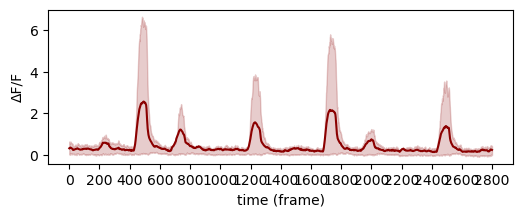

['fish2' 'fish3' 'fish4' 'fish5']


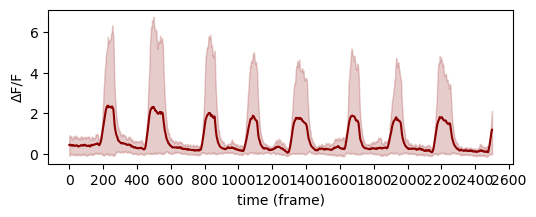

['fish1' 'fish2']


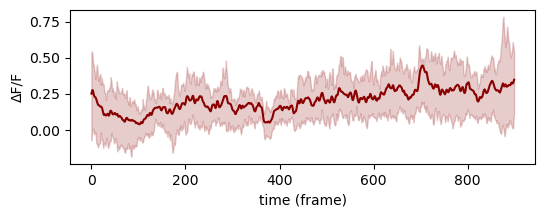

['fish1' 'fish3']


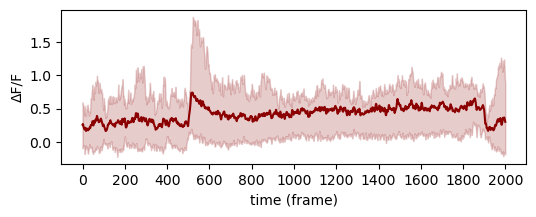

['fish1' 'fish2']


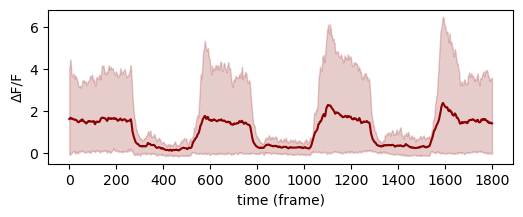

['fish1' 'fish2' 'fish3']


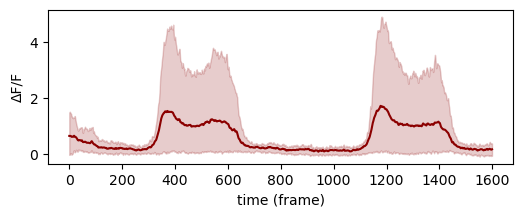

['fish1' 'fish2' 'fish4' 'fish7']


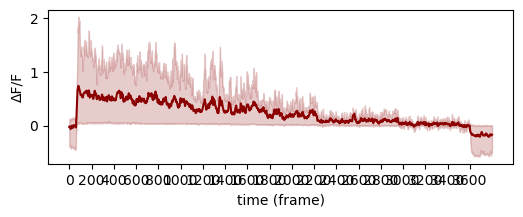

['receptive_fields\\fish1' 'receptive_fields\\fish2']


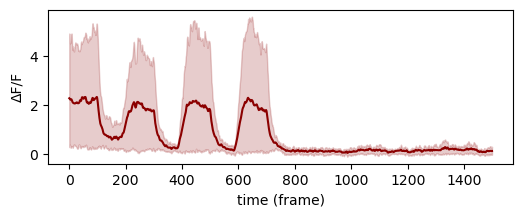

['NI_spontaneous\\fish10_6dpf' 'NI_spontaneous\\fish1_5dpf'
 'NI_spontaneous\\fish3_5dpf' 'NI_spontaneous\\fish4_5dpf'
 'NI_spontaneous\\fish5_5dpf' 'NI_spontaneous\\fish6_6dpf'
 'NI_spontaneous\\fish7_6dpf' 'NI_spontaneous\\fish8_6dpf']


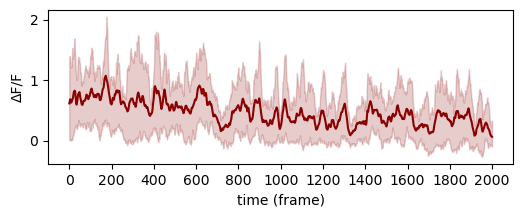

['bilat_eye_ablation\\fish1' 'bilat_eye_ablation\\fish2'
 'bilat_eye_ablation\\fish5']


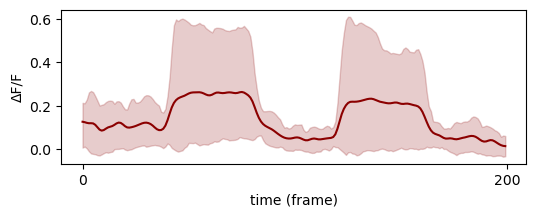

In [40]:
for protocol_directory in protocol_directories:
    print(protocol_metadata[protocol_directory]["fish_directories"].unique())
    plt.figure( figsize = (6,2))
    plt.xticks(range(0,3700,200))
    plt.plot(protocol_traces[protocol_directory].transpose().mean(), color = "darkred")
    plt.fill_between(
        range(0,protocol_traces[protocol_directory].shape[0]),
        protocol_traces[protocol_directory].transpose().quantile(0.16),
        protocol_traces[protocol_directory].transpose().quantile(0.84),
        alpha = 0.2, color = "darkred"
    )
    plt.xlabel("time (frame)")
    plt.ylabel("ÃƒÆ’Ã…Â½ÃƒÂ¢Ã¢â€šÂ¬Ã‚ÂF/F")
    plt.show()
    

In [41]:
mean_dark_stimulus_trace = protocol_traces["dark_stim/"].mean(axis = 1)

In [42]:
positive_correlation_traces = pd.DataFrame()
negative_correlation_traces = pd.DataFrame()

positive_correlation_count = 0
negative_correlation_count = 0
neutral_correlation_count = 0
correlation_coefficients = []

for trace_selection in protocol_traces["dark_stim/"].keys():

    correlation_coefficients.append(sc.spearmanr(mean_dark_stimulus_trace, protocol_traces["dark_stim/"][trace_selection])[0])

    if sc.spearmanr(mean_dark_stimulus_trace, protocol_traces["dark_stim/"][trace_selection])[0]>.5:
        positive_correlation_traces[trace_selection] = protocol_traces["dark_stim/"][trace_selection]
        positive_correlation_count +=1
    elif sc.spearmanr(mean_dark_stimulus_trace, protocol_traces["dark_stim/"][trace_selection])[0]<-.25:
        negative_correlation_traces[trace_selection] = protocol_traces["dark_stim/"][trace_selection]
        negative_correlation_count +=1
    else: neutral_correlation_count +=1


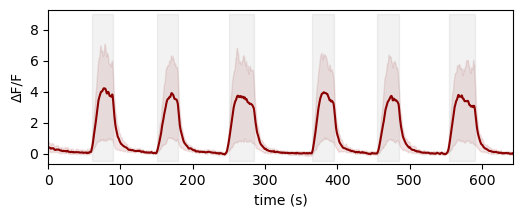

In [43]:

plt.figure( figsize = (6,2))
plt.plot(positive_correlation_traces.mean(axis =1), color = "darkred")
plt.fill_between(
    range(0,positive_correlation_traces.shape[0]),
    positive_correlation_traces.quantile(0.16, axis = 1),
    positive_correlation_traces.quantile(0.84, axis = 1),
    alpha = 0.1, color = "darkred"
)

plt.xticks([(trace_selection+220)*2.78 for trace_selection in range(0,1000,100)], range(0,1000,100))


figure = plt.gcf()
axes = figure.gca()
for stimulus_start_frame,stimulus_duration_frames in zip([280,370, 470, 585, 675, 775], [trace_selection*2.78 for trace_selection in [30,30,35,30,30,35]]):
    stimulus_rectangle = Rectangle((stimulus_start_frame*2.78,-.5), stimulus_duration_frames, 9.5, color = "gray", alpha = .1)
    axes.add_patch(stimulus_rectangle)

plt.xlim([220*2.78,2400])

plt.xlabel("time (stimulus_start_frame)")
plt.ylabel("ÃƒÆ’Ã…Â½ÃƒÂ¢Ã¢â€šÂ¬Ã‚ÂF/F")
plt.savefig("C:/Users/mtuffery/Desktop/upright_inverted.svg", transparent = True)

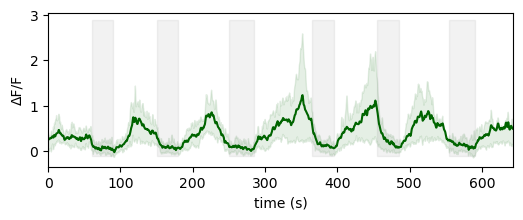

In [44]:
plt.figure( figsize = (6,2))

plt.xticks([(trace_selection+220)*2.78 for trace_selection in range(0,1000,100)], range(0,1000,100))
plt.plot(negative_correlation_traces.mean(axis =1), color = "darkgreen")
plt.fill_between(
    range(0,negative_correlation_traces.shape[0]),
    negative_correlation_traces.quantile(0.16, axis = 1),
    negative_correlation_traces.quantile(0.84, axis = 1),
    alpha = 0.1, color = "darkgreen"
)

figure = plt.gcf()
axes = figure.gca()
for stimulus_start_frame,stimulus_duration_frames in zip([280,370, 470, 585, 675, 775], [trace_selection*2.78 for trace_selection in [30,30,35,30,30,35]]):
    stimulus_rectangle = Rectangle((stimulus_start_frame*2.78,-.1), stimulus_duration_frames, 3, color = "gray", alpha = .1)
    axes.add_patch(stimulus_rectangle)

plt.xlim([220*2.78,2400])

plt.xlabel("time (stimulus_start_frame)")
plt.ylabel("ÃƒÆ’Ã…Â½ÃƒÂ¢Ã¢â€šÂ¬Ã‚ÂF/F")
plt.savefig("C:/Users/mtuffery/Desktop/negative_correlation_count.svg", transparent = True)

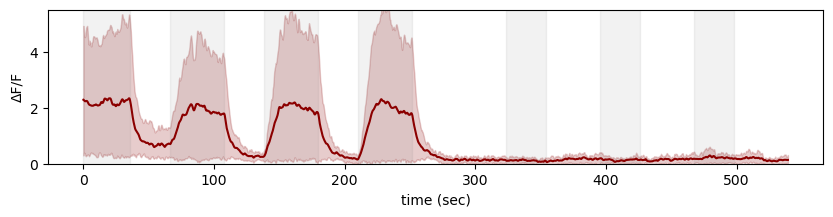

In [45]:
protocol_directory = "receptive_fields"

plt.figure( figsize = (10,2))
plt.xticks([trace_selection*2.78 for trace_selection in range(0,1000,100)], range(0,1000,100))
plt.plot(protocol_traces[protocol_directory].transpose().mean(), color = "darkred")
plt.fill_between(
    range(0,protocol_traces[protocol_directory].shape[0]),
    protocol_traces[protocol_directory].transpose().quantile(0.16),
    protocol_traces[protocol_directory].transpose().quantile(0.84),
    alpha = 0.2, color = "darkred"
)

figure = plt.gcf()
axes = figure.gca()
stimulus_rectangle = Rectangle((0,-1), 100, 6.5, color = "gray", alpha = .1)
axes.add_patch(stimulus_rectangle)
stimulus_rectangle = Rectangle((185,-1), 115, 6.5, color = "gray", alpha = .1)
axes.add_patch(stimulus_rectangle)

stimulus_rectangle = Rectangle((385,-1), 115, 6.5, color = "gray", alpha = .1)
axes.add_patch(stimulus_rectangle)
stimulus_rectangle = Rectangle((585,-1), 115, 6.5, color = "gray", alpha = .1)
axes.add_patch(stimulus_rectangle)


stimulus_rectangle = Rectangle((900,-1), 85, 6.5, color = "gray", alpha = .1)
axes.add_patch(stimulus_rectangle)
stimulus_rectangle = Rectangle((1100,-1), 85, 6.5, color = "gray", alpha = .1)
axes.add_patch(stimulus_rectangle)

stimulus_rectangle = Rectangle((1300,-1), 85, 6.5, color = "gray", alpha = .1)
axes.add_patch(stimulus_rectangle)



plt.ylim([0,5.5])



plt.xlabel("time (sec)")
plt.ylabel("ÃƒÆ’Ã…Â½ÃƒÂ¢Ã¢â€šÂ¬Ã‚ÂF/F")
plt.savefig("C:/Users/mtuffery/Desktop/black_red_squares.svg", transparent = True)
plt.show()

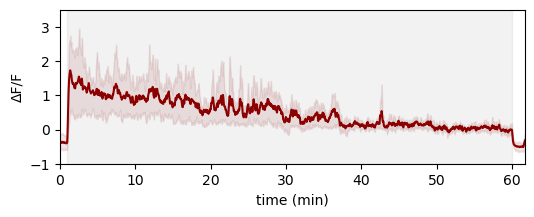

In [46]:
protocol_directory = "DARK_1HOUR/"



selected_unit_ids = ["fish1_0", "fish1_1", "fish1_10", "fish1_2", "fish1_3", "fish1_6","fish1_7", "fish1_8", "fish2_0", "fish2_1", "fish2_2","fish2_6", "fish2_7", "fish2_8", "fish4_0", "fish4_1"]

plt.figure( figsize = (6,2))
plt.xticks(range(0,3601,600),range(0,61,10))
plt.plot(protocol_traces[protocol_directory][selected_unit_ids].transpose().mean(), color = "darkred")
plt.fill_between(
    range(0,protocol_traces[protocol_directory][selected_unit_ids].shape[0]),
    protocol_traces[protocol_directory][selected_unit_ids].transpose().quantile(0.16),
    protocol_traces[protocol_directory][selected_unit_ids].transpose().quantile(0.84),
    alpha = 0.1, color = "darkred"
)

figure = plt.gcf()
axes = figure.gca()
stimulus_rectangle = Rectangle((60,-1), 3540, 4.5, color = "gray", alpha = .1)
axes.add_patch(stimulus_rectangle)
plt.ylim([-1,3.5])
plt.xlim([0,3700])

plt.xlabel("time (min)")
plt.ylabel("ÃƒÆ’Ã…Â½ÃƒÂ¢Ã¢â€šÂ¬Ã‚ÂF/F")
plt.savefig("C:/Users/mtuffery/Desktop/1_hour_dark.svg", transparent = True)
plt.show()

In [47]:
stimulus_start_frames =  [180, 430, 680, 930, 1180, 1430, 1680, 1930, 2180, 2430]
stimulus_contrast_labels = ["0.5","1","0.66","0.25","0.75"]*2
response_window_frames = 100

contrast_response_data = pd.DataFrame()

for stimulus_start_frame, contrast_label in zip(stimulus_start_frames, stimulus_contrast_labels):
    
    unit_peak_responses = list(protocol_traces["black_white_diff_intensties/"].iloc[stimulus_start_frame:stimulus_start_frame+response_window_frames].max())

    if contrast_label not in contrast_response_data.keys():
        contrast_response_data[contrast_label] = unit_peak_responses
    else:
        contrast_response_data[contrast_label] = (contrast_response_data[contrast_label] +np.array(unit_peak_responses))/2


contrast_response_data["max_resp"] = list(contrast_response_data[stimulus_contrast_labels].max(axis = 1))

['fish1_0' 'fish1_1' 'fish1_11' 'fish1_2' 'fish1_3' 'fish1_4' 'fish1_5'
 'fish1_7' 'fish1_8' 'fish2_2' 'fish2_6' 'fish2_8' 'fish2_9' 'fish3_0'
 'fish3_1' 'fish3_10' 'fish3_11' 'fish3_6' 'fish3_7' 'fish4_0' 'fish4_1'
 'fish4_10' 'fish4_2' 'fish4_8' 'fish4_9' 'fish5_0' 'fish5_1' 'fish5_10'
 'fish5_11' 'fish5_12' 'fish5_13' 'fish5_14' 'fish5_9' 'fish6_0' 'fish6_1'
 'fish6_2' 'fish6_4' 'fish6_5' 'fish6_6' 'fish6_7' 'fish6_8' 'fish7_0'
 'fish7_1' 'fish7_12' 'fish7_13' 'fish7_14' 'fish7_15' 'fish7_16'
 'fish7_18' 'fish7_2' 'fish8_0' 'fish8_6' 'fish8_8']


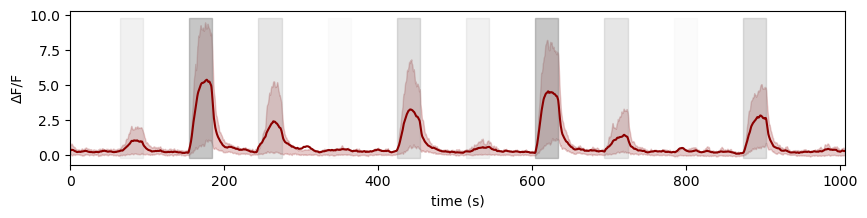

In [48]:
responsive_unit_mask = contrast_response_data["max_resp"]>1.5#contrast_response_data["max_resp"].median()

selected_unit_ids = np.array(protocol_traces["black_white_diff_intensties/"].keys())[responsive_unit_mask]
print(selected_unit_ids)
trace_selection = protocol_traces["black_white_diff_intensties/"][selected_unit_ids]

plt.figure( figsize = (10,2))
plt.xticks(range(0,1500,200))
plt.xticks([trace_selection*2.78 for trace_selection in range(0,1100,200)], range(0,1100,200))
plt.xlabel("time (stimulus_start_frame)")
plt.ylabel("ÃƒÆ’Ã…Â½ÃƒÂ¢Ã¢â€šÂ¬Ã‚ÂF/F")
plt.plot(trace_selection.transpose().mean(), color = "darkred")
plt.fill_between(
    range(0,trace_selection.shape[0]),
    trace_selection.transpose().quantile(0.16),
    trace_selection.transpose().quantile(0.84),
    alpha = 0.2, color = "darkred"
)

figure = plt.gcf()
axes = figure.gca()
stimulus_duration_seconds = 30*2.78
for trace_selection,selected_unit_ids in zip(stimulus_start_frames, stimulus_contrast_labels):
    stimulus_rectangle = Rectangle((trace_selection,-0.2), stimulus_duration_seconds, 10, color = "gray", alpha = ((float(selected_unit_ids)/1.5)**2))
    axes.add_patch(stimulus_rectangle)
plt.xlim([0,2800])
plt.savefig("C:/Users/mtuffery/Desktop/darksteps.svg", transparent = True)

plt.show()


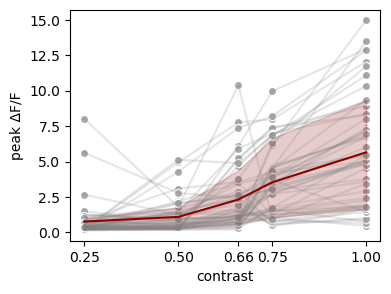

In [49]:

plt.figure(figsize = (4,3))
plt.plot(
    [0.25,0.5,0.66,0.75,1],
    contrast_response_data[["0.25","0.5", "0.66", "0.75", "1"]][responsive_unit_mask].transpose(),
    alpha=0.2,
    color = "gray"

)
    



for contrast_label in stimulus_contrast_labels:
    plt.scatter(
        
        [float(contrast_label)]*contrast_response_data[responsive_unit_mask].shape[0],
        contrast_response_data[contrast_label][responsive_unit_mask],

        color = "darkgray",
        edgecolors = "white"
    )
    
plt.plot(
    [0.25,0.5,0.66,0.75,1],
    contrast_response_data[["0.25","0.5", "0.66", "0.75", "1"]][responsive_unit_mask].mean(), color = "darkred"
)

plt.fill_between(
    [0.25,0.5,0.66,0.75,1], 
    contrast_response_data[["0.25","0.5", "0.66", "0.75", "1"]][responsive_unit_mask].quantile(0.16),
    contrast_response_data[["0.25","0.5", "0.66", "0.75", "1"]][responsive_unit_mask].quantile(0.84),
    alpha = 0.2, color = "darkred"

)

plt.xticks([0.25,0.5,0.66,0.75,1])
plt.xlabel("contrast")

plt.ylabel("peak ÃƒÆ’Ã…Â½ÃƒÂ¢Ã¢â€šÂ¬Ã‚ÂF/F")
        
plt.savefig("C:/Users/mtuffery/Desktop/correlation.svg", transparent = True)

plt.show()

In [50]:
responsive_unit_peak_responses = []
responsive_unit_contrast_values = []
contrast_levels = ["0.25","0.5", "0.66", "0.75", "1"]

for contrast_label in contrast_levels:
    responsive_unit_contrast_values += [float(contrast_label)]*contrast_response_data[responsive_unit_mask].shape[0]
    responsive_unit_peak_responses += list(contrast_response_data[contrast_label][responsive_unit_mask])

print(sc.spearmanr(responsive_unit_contrast_values,responsive_unit_peak_responses))

SignificanceResult(statistic=0.6865945090127551, pvalue=2.77302030248487e-38)
